# Étude de cas 1 — Jalon 2 : Voir les chiffres (CNN et auto-encodeur)
**M2 SDIA – Advanced AI · ENSET Mohammedia · 2026–2027**

Plan : 0 Configuration · 1 Données · 2 CNN de référence · 3 Choix de conception · 4 Détecteur d'altération · 5 Auto-encodeur débruiteur · 6 Vérification théorique · 7 Test final et sauvegarde



## 0. Configuration

In [1]:
import os, json, time, random, glob
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.ndimage import gaussian_filter

SEED = 0
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| NumPy", np.__version__)

JOURNAL = "journal_experiences.json"
def journaliser(nom, hyperparametres, metriques, jalon=2):
    j = json.load(open(JOURNAL)) if os.path.exists(JOURNAL) else []
    j.append({"jalon": jalon, "date": time.strftime("%Y-%m-%d %H:%M:%S"),
              "nom": nom, "hyperparametres": hyperparametres, "metriques": metriques})
    json.dump(j, open(JOURNAL, "w"), indent=2, ensure_ascii=False)
    print(f"[Journal] {nom} : {metriques}")

TensorFlow 2.21.0 | NumPy 2.1.3


## 1. Données et métriques

In [2]:
def trouver(nom):
    for d in [".", "data", "/content", "/content/data", "/content/drive/MyDrive"]:
        c = sorted(glob.glob(os.path.join(d, f"*{nom}*.npz")))
        if c: return c[0]
    raise FileNotFoundError(f"{nom} introuvable : téléversez les .npz dans Colab")

A = np.load(trouver("domaineA"), allow_pickle=True)
B = np.load(trouver("domaineB"), allow_pickle=True)
S, L_MAX = ["train", "val", "test"], 5

XA = {s: A[f"X_{s}"].astype("float32")[..., None] / 255.0 for s in S}
XB = {s: B[f"X_{s}"].astype("float32")[..., None] / 255.0 for s in S}

def encoder(montants):
    """Lecture par positions : montant cadré à droite, jeton 10 = case vide (à gauche)."""
    Y = {f"pos_{i}": np.full(len(montants), 10, "int32") for i in range(L_MAX)}
    for n, m in enumerate(montants):
        m = str(m)
        for k, ch in enumerate(m):
            Y[f"pos_{L_MAX - len(m) + k}"][n] = int(ch)
    return Y, np.array([len(str(m)) for m in montants])

YA, LA, YB, LB = {}, {}, {}, {}
for s in S:
    YA[s], LA[s] = encoder(A[f"montant_{s}"])
    YB[s], LB[s] = encoder(B[f"montant_{s}"])

ALT = {s: A[f"altere_{s}"].astype(int) for s in S}
cle_type = lambda s: [k for k in A.files if "type" in k and k.endswith(s)][0]
TYPE = {s: A[cle_type(s)] for s in S}
n0, n1 = np.bincount(ALT["train"])
poids_alteration = {0: 1.0, 1: float(n0 / n1)}
print("A :", {s: len(XA[s]) for s in S}, "| B :", {s: len(XB[s]) for s in S})
print("altérés (train) :", n1, "/", n0 + n1, "| types :", np.unique(TYPE["train"]))

# ---- métriques ----
def en_dict(P):
    return P if isinstance(P, dict) else {f"pos_{i}": P[i] for i in range(L_MAX)}

def lectures(Y, P):
    P = en_dict(P)
    pred = np.column_stack([P[f"pos_{i}"].argmax(1) for i in range(L_MAX)])
    vrai = np.column_stack([Y[f"pos_{i}"] for i in range(L_MAX)])
    return pred == vrai                       # (N, 5) booléens

def exactitude(Y, P):   return lectures(Y, P).all(1).mean()
def par_position(Y, P): return lectures(Y, P).mean(0).round(3)
def par_longueur(Y, P, L):
    ok = lectures(Y, P).all(1)
    return {int(l): round(float(ok[L == l].mean()), 3) for l in np.unique(L)}

def evaluer_alteration(y, score, fpr_cible=0.05):
    fpr, tpr, seuils = roc_curve(y, score)
    i = np.where(fpr <= fpr_cible)[0][-1]
    return roc_auc_score(y, score), tpr[i], seuils[i]

A : {'train': 15000, 'val': 3000, 'test': 5000} | B : {'train': 600, 'val': 400, 'test': 3000}
altérés (train) : 1480 / 15000 | types : [0 1 2]


## 2. CNN de référence (mêmes 5 têtes que le MLP)

In [3]:
def construire_cnn(filtres=(32, 64, 64), noyau=3, dense=128, agregation="flatten", nom="CNN_Reference"):
    x = inp = layers.Input((32, 128, 1))
    for f in filtres:
        x = layers.Conv2D(f, noyau, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x) if agregation == "flatten" else layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense, activation="relu", name="couche_dense")(x)
    sorties = [layers.Dense(11, activation="softmax", name=f"pos_{i}")(x) for i in range(L_MAX)]
    return keras.Model(inp, sorties, name=nom)

EPOCHS = 10
def entrainer(model, epochs=EPOCHS):
    model.compile("adam",
                  loss={f"pos_{i}": "sparse_categorical_crossentropy" for i in range(L_MAX)},
                  metrics={f"pos_{i}": "accuracy" for i in range(L_MAX)})
    model.fit(XA["train"], YA["train"], validation_data=(XA["val"], YA["val"]),
              epochs=epochs, batch_size=64, verbose=0)
    return model

cnn_ref = entrainer(construire_cnn())
P = cnn_ref.predict(XA["val"], verbose=0)
acc_ref = exactitude(YA["val"], P)
print(f"CNN référence — montants exacts (val A) : {acc_ref:.4f}")
print("par position :", par_position(YA["val"], P))
print("par longueur :", par_longueur(YA["val"], P, LA["val"]))
journaliser("CNN_Reference", {"filtres": [32, 64, 64], "noyau": 3, "dense": 128, "epochs": EPOCHS},
            {"acc_exacte_val": float(acc_ref)})
cnn_ref.summary()

CNN référence — montants exacts (val A) : 0.4167
par position : [0.91  0.786 0.694 0.753 0.894]
par longueur : {1: 0.934, 2: 0.737, 3: 0.527, 4: 0.24, 5: 0.081}
[Journal] CNN_Reference : {'acc_exacte_val': 0.4166666666666667}


Model: "CNN_Reference"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 32, 128,   │          0 │ -                 │
│ (InputLayer)        │ 1)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 32, 128,   │        320 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 16, 64,    │          0 │ conv2d[0][0]      │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 16, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 8, 32, 64) │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 8, 32, 64) │     36,928 │ max_pooling2d_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 4, 16, 64) │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 4096)      │          0 │ max_pooling2d_2[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ couche_dense        │ (None, 128)       │    524,416 │ flatten[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos_0 (Dense)       │ (None, 11)        │      1,419 │ couche_dense[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos_1 (Dense)       │ (None, 11)        │      1,419 │ couche_dense[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos_2 (Dense)       │ (None, 11)        │      1,419 │ couche_dense[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos_3 (Dense)       │ (None, 11)        │      1,419 │ couche_dense[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pos_4 (Dense)       │ (None, 11)        │      1,419 │ couche_dense[0][… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,761,767 (6.72 MB)

 Trainable params: 587,255 (2.24 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,174,512 (4.48 MB)

## 3. Choix de conception (champ réceptif et nombre de paramètres)

In [4]:
keras.backend.clear_session()   # purge un éventuel scope bloqué par une erreur précédente

variantes = {
    "noyau 5x5":      dict(noyau=5),
    "2 blocs":        dict(filtres=(32, 64)),
    "agregation GAP": dict(agregation="gap"),
}
NOM_REF = "référence (3 blocs, 3x3, flatten)"
modeles = {NOM_REF: cnn_ref}                      # on garde TOUS les modèles entraînés
lignes = [{"modèle": NOM_REF, "params": cnn_ref.count_params(), "acc_val": acc_ref}]
for nom, kw in variantes.items():
    m = entrainer(construire_cnn(nom="CNN_variante_" + str(len(lignes)), **kw))
    modeles[nom] = m
    a = exactitude(YA["val"], m.predict(XA["val"], verbose=0))
    lignes.append({"modèle": nom, "params": m.count_params(), "acc_val": a})
    journaliser("Variante_" + nom, {**{k: str(v) for k, v in kw.items()}, "epochs": EPOCHS}, {"acc_exacte_val": float(a)})

tableau = pd.DataFrame(lignes).round(4)
display(tableau)

# modèle retenu = meilleur sur la VALIDATION (c'est lui qui passera le test en section 7)
nom_retenu = tableau.loc[tableau["acc_val"].idxmax(), "modèle"]
cnn_retenu = modeles[nom_retenu]
print("Modèle retenu :", nom_retenu)

[Journal] Variante_noyau 5x5 : {'acc_exacte_val': 0.5106666666666667}
[Journal] Variante_2 blocs : {'acc_exacte_val': 0.253}
[Journal] Variante_agregation GAP : {'acc_exacte_val': 0.054}


,modèle,params,acc_val
0,"référence (3 blocs, 3x3, flatten)",587255,0.4167
1,noyau 5x5,686071,0.5107
2,2 blocs,2123191,0.2530
3,agregation GAP,71159,0.0540


Modèle retenu : noyau 5x5


**Lecture des choix de conception**

| Variante | Paramètres | Exactitude val |
|---|---|---|
| Référence (3 blocs, 3×3, flatten) | 587 255 | 0,417 |
| Noyau 5×5 (**retenu**) | 686 071 | 0,511 |
| 2 blocs | 2 123 191 | 0,253 |
| Agrégation GAP | 71 159 | 0,054 |

- **Noyau 5×5 :** +10 points pour seulement +17 % de paramètres. Deux convolutions 5×5 voient une zone plus large qu'avec 3×3, ce qui aide à lire un chiffre entier et ses voisins.
- **2 blocs :** moins bon (0,253). Le champ réceptif est plus petit, et l'aplatissement produit 16 384 valeurs, donc 2,1 M de paramètres. Il y a probablement du surapprentissage, que nous n’avons pas vérifié avec les courbes d’entraînement
- **GAP :** quasi nul (0,054). La moyenne globale supprime l'information de position, or la lecture par positions en a besoin.
- Le modèle retenu est choisi sur la **validation**.

## 3bis. Comparaison avec le MLP de référence (Jalon 1)

Le MLP de référence est celui du Jalon 1 (256-128, 1 088 823 paramètres, mêmes données, même encodage par positions). Son score vient de notre notebook du Jalon 1, sur la validation du scanner A.

| Mesure (validation A) | MLP référence | CNN référence | CNN retenu (5×5) |
|---|---|---|---|
| Montants exacts | 0,059 | 0,417 | 0,511 |
| 1 chiffre | 0,511 | 0,934 | – |
| 2 chiffres | 0,131 | 0,737 | – |
| 3 chiffres | 0,042 | 0,527 | – |
| 4 chiffres | 0,006 | 0,240 | – |
| 5 chiffres | 0,002 | 0,081 | – |
| Position unités | 0,449 | 0,894 | – |
| Position dizaines | 0,329 | 0,753 | – |
| Position centaines | 0,402 | 0,694 | – |
| Position milliers | 0,614 | 0,786 | – |
| Position dizaines de mille | 0,835 | 0,910 | – |

Le meilleur essai du MLP au Jalon 1 (augmentation par décalage ±8 px) atteint 0,162 en validation. Sur le test, le MLP final fait 0,097 et le CNN retenu 0,460.

**Conclusions**
- Le CNN bat le MLP à tous les niveaux : environ 7 fois la référence et 3 fois le meilleur essai du MLP, et **sans aucune augmentation**. La convolution partage ses poids entre les positions, alors que le MLP doit réapprendre chaque chiffre à chaque emplacement.
- L'écart est maximal sur les montants courts (2 chiffres : 0,737 contre 0,131).
- Les deux modèles s'effondrent sur les montants longs (5 chiffres : 0,081 pour le CNN). La lecture par positions fixes ne suffit pas, d'où le Jalon 4 (lecture en séquence).
- Les positions élevées paraissent faciles parce qu'elles sont souvent vides (classe 10) : leur exactitude est gonflée.

**Limites de la comparaison**
- Budget différent : le MLP s'arrêtait sur la perte de validation (jusqu'à 40 époques), le CNN fait 10 époques fixes.
- Dans le notebook du Jalon 2, les positions sont numérotées à l'envers du Jalon 1 (pos_4 = unités). Le tableau est remis dans l'ordre du Jalon 1.

## 4. Détecteur d'altération (CNN binaire)

In [5]:
def construire_detecteur():
    x = inp = layers.Input((32, 128, 1))
    for f in (32, 64, 64):
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Flatten()(x)
    x = layers.Dropout(0.3)(layers.Dense(64, activation="relu")(x))
    return keras.Model(inp, layers.Dense(1, activation="sigmoid")(x), name="Detecteur_Alteration")

det = construire_detecteur()
det.compile("adam", "binary_crossentropy", metrics=[keras.metrics.AUC(name="auc")])
det.fit(XA["train"], ALT["train"], validation_data=(XA["val"], ALT["val"]),
        epochs=EPOCHS, batch_size=64, class_weight=poids_alteration, verbose=0)

score_val = det.predict(XA["val"], verbose=0).ravel()
auc, rappel, seuil = evaluer_alteration(ALT["val"], score_val)
print(f"AUC val = {auc:.4f} (cible ≥ 0,95) | rappel à 5 % de fausses alertes = {rappel:.3f} | seuil = {seuil:.3f}")

# altérations manquées par type (au seuil retenu)
masque = ALT["val"] == 1
for t in np.unique(TYPE["val"][masque]):
    sel = masque & (TYPE["val"] == t)
    print(f"  type « {t} » : rappel = {(score_val[sel] >= seuil).mean():.3f}  (n = {sel.sum()})")
journaliser("Detecteur_Alteration", {"blocs": 3, "dropout": 0.3, "class_weight": poids_alteration},
            {"auc_val": float(auc), "rappel_5fpr": float(rappel)})

AUC val = 0.9925 (cible ≥ 0,95) | rappel à 5 % de fausses alertes = 0.979 | seuil = 0.187
  type « 1 » : rappel = 0.972  (n = 108)
  type « 2 » : rappel = 0.983  (n = 177)
[Journal] Detecteur_Alteration : {'auc_val': 0.9924706794610836, 'rappel_5fpr': 0.9789473684210527}


**Seuil d'alerte du détecteur**

Sur la validation, l'AUC est de 0,9925 et le rappel de 0,979 à 5 % de fausses alertes. Le seuil correspondant est 0,187.

- Une fausse alerte envoie un chèque légitime vers un opérateur : un coût de traitement, sans perte d'argent. Une altération manquée laisse passer une fraude.
- On accepte donc environ 1 chèque légitime sur 20 en relecture pour attraper près de 98 % des altérations.
- Rappel par type d'altération : 0,972 (type 1) et 0,983 (type 2). Aucun type n'est négligé.
- Le seuil est bas à cause de la pondération des classes : le score n'est pas une probabilité calibrée.
- Ce détecteur n'a été évalué que sur le scanner A.

## 5. Auto-encodeur débruiteur (imiter le scanner B)

A            : fond (médiane) = 0.00 | encre (max moyen) = 0.92
B            : fond (médiane) = 0.18 | encre (max moyen) = 0.86
A corrompue  : fond (médiane) = 0.18 | encre (max moyen) = 0.88  <- doit ressembler à B
Scanner B (val) — brut : 0.0050 | contraste étiré : 0.0225 | débruité (AE) : 0.4800
sortie de l'AE sur B : min/max = 0.0 0.967 (si max ≈ 0 : l'AE a effondré)
[Journal] AutoEncodeur_Debruiteur : {'acc_B_val_brut': 0.005, 'acc_B_val_etire': 0.0225, 'acc_B_val_debruite': 0.48}


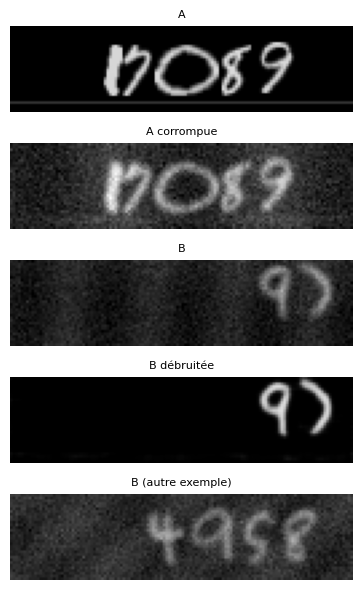

In [6]:
rng = np.random.default_rng(SEED)

# --- calibrage : comparer la luminosité de A, de B et de A corrompue ---
def stats(X): return f"fond (médiane) = {np.median(X):.2f} | encre (max moyen) = {X.max(axis=(1, 2, 3)).mean():.2f}"

def corrompre(X, lot=3000):
    """Imite B : encre très pâle, flou, fond gris à BANDES VERTICALES, bruit."""
    sorties, col = [], np.arange(128).reshape(1, 1, 128, 1)
    for i in range(0, len(X), lot):
        x = X[i:i + lot]; n = len(x)
        x = x * rng.uniform(0.55, 0.90, (n, 1, 1, 1))                 # encre pâle
        x = gaussian_filter(x, sigma=(0, rng.uniform(0.7, 1.3), rng.uniform(0.7, 1.3), 0))
        bandes = 0.07 * np.sin(rng.uniform(0.10, 0.30, (n, 1, 1, 1)) * col
                               + rng.uniform(0, 6.28, (n, 1, 1, 1)))   # motif de sécurité
        x = x + rng.uniform(0.10, 0.20, (n, 1, 1, 1)) + bandes + rng.normal(0, 0.05, x.shape)
        sorties.append(np.clip(x, 0, 1).astype("float32"))
    return np.concatenate(sorties)

Xc_train, Xc_val = corrompre(XA["train"]), corrompre(XA["val"])
print("A            :", stats(XA["val"]))
print("B            :", stats(XB["val"]))
print("A corrompue  :", stats(Xc_val), " <- doit ressembler à B")

# perte pondérée : l'encre est rare, sans pondération l'AE apprend à sortir du noir
def mse_encre(y, p):
    return tf.reduce_mean((1.0 + 9.0 * y) * tf.square(y - p))

def construire_ae():
    x = inp = layers.Input((32, 128, 1))
    x = layers.MaxPooling2D(2, padding="same")(layers.Conv2D(32, 3, padding="same", activation="relu")(x))
    x = layers.MaxPooling2D(2, padding="same")(layers.Conv2D(64, 3, padding="same", activation="relu")(x))
    x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(x)
    x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(x)
    return keras.Model(inp, layers.Conv2D(1, 3, padding="same", activation="sigmoid")(x), name="AutoEncodeur")

ae = construire_ae()
ae.compile("adam", mse_encre)
ae.fit(Xc_train, XA["train"], validation_data=(Xc_val, XA["val"]), epochs=12, batch_size=64, verbose=0)

# intérêt : lecture de B (validation) avec le CNN retenu — brut, contraste étiré, débruité
def etirer(X):
    lo = np.percentile(X, 5, axis=(1, 2, 3), keepdims=True)
    hi = np.percentile(X, 99.5, axis=(1, 2, 3), keepdims=True)
    return np.clip((X - lo) / (hi - lo + 1e-6), 0, 1).astype("float32")

XB_net = ae.predict(XB["val"], verbose=0)
acc_brut = exactitude(YB["val"], cnn_retenu.predict(XB["val"], verbose=0))
acc_etire = exactitude(YB["val"], cnn_retenu.predict(etirer(XB["val"]), verbose=0))
acc_net = exactitude(YB["val"], cnn_retenu.predict(XB_net, verbose=0))
print(f"Scanner B (val) — brut : {acc_brut:.4f} | contraste étiré : {acc_etire:.4f} | débruité (AE) : {acc_net:.4f}")
print("sortie de l'AE sur B : min/max =", XB_net.min().round(3), XB_net.max().round(3), "(si max ≈ 0 : l'AE a effondré)")
journaliser("AutoEncodeur_Debruiteur", {"epochs": 12, "perte": "MSE pondérée encre x10", "corruption": "pâle+flou+bandes verticales+bruit"},
            {"acc_B_val_brut": float(acc_brut), "acc_B_val_etire": float(acc_etire), "acc_B_val_debruite": float(acc_net)})

fig, ax = plt.subplots(5, 1, figsize=(6, 6))
for a, im, t in zip(ax, [XA["val"][0], Xc_val[0], XB["val"][0], XB_net[0], XB["val"][1]],
                    ["A", "A corrompue", "B", "B débruitée", "B (autre exemple)"]):
    a.imshow(im[..., 0], cmap="gray", vmin=0, vmax=1); a.set_title(t, fontsize=8); a.axis("off")
plt.tight_layout(); plt.show()

**Intérêt de l'auto-encodeur (validation B, CNN retenu)**

| Entrée du CNN | Montants exacts |
|---|---|
| Image B brute | 0,005 |
| Contraste étiré seul | 0,023 |
| **Image B débruitée par l'auto-encodeur** | **0,480** |

- Sans débruitage, le CNN entraîné sur A ne lit presque rien de B : changement de domaine.
- Étirer le contraste ne suffit pas, donc le problème n'est pas seulement une encre pâle. Le motif de fond et le flou jouent aussi.
-Notre premier auto-encodeur (corruption mal calibrée, perte non pondérée) a produit des images noires : 0,005 sur B après débruitage. Cet essai infructueux est conservé dans l’historique des expériences.
- Une fois la corruption calibrée sur B (fond de 0,18, encre proche de 0,86), le gain est très grand.
- Une fois débruité, B (0,48) est presque au niveau de A (0,51). L'écart restant vient de la lecture par positions, plus du changement de scanner.

## 6. Vérification théorique (à la main)

Entrée 32×128×1 ; trois blocs « convolution 3×3 (same) + max-pooling 2×2 » à 32, 64 et 64 filtres ; Dense 128 ; 5 têtes de 11 classes.

| Couche | Sortie | Paramètres |
|---|---|---|
| Conv 32 | 32×128×32 | 3·3·1·32 + 32 = **320** |
| Pool | 16×64×32 | 0 |
| Conv 64 | 16×64×64 | 3·3·32·64 + 64 = **18 496** |
| Pool | 8×32×64 | 0 |
| Conv 64 | 8×32×64 | 3·3·64·64 + 64 = **36 928** |
| Pool | 4×16×64 | 0 |
| Flatten | 4096 | 0 |
| Dense 128 | 128 | 4096·128 + 128 = **524 416** |
| 5 têtes | 5×11 | 5·(128·11 + 11) = **7 095** |
| **Total** | | **587 255** |

**Champ réceptif (référence 3×3) :** conv3 → 3 ; pool → 4 ; conv3 → 8 ; pool → 10 ; conv3 → 18 ; pool → **22 px**.
Un neurone de la dernière carte voit environ 22×22 pixels, soit à peu près la hauteur d'un chiffre (18 à 26 px) : il voit un chiffre entier, mais pas le montant (128 px de large). C'est la couche dense qui relie les cases entre elles.

**Modèle retenu (noyaux 5×5) :** 832 + 51 264 + 102 464 + 524 416 + 7 095 = **686 071** paramètres (confirmé par le tableau de la section 3). Champ réceptif : 5 → 6 → 14 → 16 → 32 → **36 px**, supérieur à la hauteur d'un chiffre. Il voit donc le chiffre et une partie de ses voisins, ce qui explique le gain par rapport au 3×3.

Le code ci-dessous confirme 22 px et 587 255 paramètres pour la référence.

In [7]:
# vérification par le code
rf, saut = 1, 1
for k, p in [(3, 2)] * 3:                      # (noyau, pooling) de chaque bloc
    rf += (k - 1) * saut; saut *= p
    rf += (p - 1) * (saut // p)
print("champ réceptif calculé :", rf, "px")
print("paramètres du modèle   :", cnn_ref.count_params(), "(attendu 587 255)")

champ réceptif calculé : 22 px
paramètres du modèle   : 587255 (attendu 587 255)


## 7. Test final (une seule fois) et sauvegarde

In [8]:
# le test sert UNE fois, pour le modèle retenu sur la validation (section 3)
P_A = cnn_retenu.predict(XA["test"], verbose=0)
acc_A = exactitude(YA["test"], P_A)
auc_A, rappel_A, _ = evaluer_alteration(ALT["test"], det.predict(XA["test"], verbose=0).ravel())
acc_B = exactitude(YB["test"], cnn_retenu.predict(ae.predict(XB["test"], verbose=0), verbose=0))

print("Modèle retenu :", nom_retenu)
print(f"Montants exacts A (test) : {acc_A:.4f}  | cible ≥ 0,85")
print(f"  par longueur : {par_longueur(YA['test'], P_A, LA['test'])}")
print(f"AUC altérations A (test) : {auc_A:.4f}  | cible ≥ 0,95  (rappel à 5 % FP : {rappel_A:.3f})")
print(f"Montants exacts B débruité (test) : {acc_B:.4f} | cible ≥ 0,70")
journaliser("TEST_FINAL", {"modele": nom_retenu},
            {"acc_A": float(acc_A), "auc_alt_A": float(auc_A), "acc_B_debruite": float(acc_B)})

# sauvegarde
cnn_ref.save("cnn_reference.keras")          # CNN de référence (3 blocs, 3x3)
cnn_retenu.save("cnn_retenu.keras")          # modèle retenu sur la validation
det.save("detecteur_alteration.keras")
ae.save("autoencodeur_debruiteur.keras")   # recharger avec compile=False (perte personnalisée)
print("Modèles sauvegardés :", [f for f in os.listdir(".") if f.endswith(".keras")])

try:
    from google.colab import files
    for f in ["cnn_reference.keras", "cnn_retenu.keras", "detecteur_alteration.keras",
              "autoencodeur_debruiteur.keras", JOURNAL]:
        files.download(f)
except ImportError:
    pass

Modèle retenu : noyau 5x5
Montants exacts A (test) : 0.4600  | cible ≥ 0,85
  par longueur : {1: 0.938, 2: 0.769, 3: 0.584, 4: 0.305, 5: 0.11}
AUC altérations A (test) : 0.9927  | cible ≥ 0,95  (rappel à 5 % FP : 0.968)
Montants exacts B débruité (test) : 0.4223 | cible ≥ 0,70
[Journal] TEST_FINAL : {'acc_A': 0.46, 'auc_alt_A': 0.992653729301898, 'acc_B_debruite': 0.42233333333333334}
Modèles sauvegardés : ['cnn_reference.keras', 'autoencodeur_debruiteur.keras', 'detecteur_alteration.keras', 'cnn_retenu.keras']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Écart aux cibles (test, une seule évaluation)

| Exigence | Cible | Obtenu | Écart |
|---|---|---|---|
| Montants exacts, scanner A | ≥ 0,85 | 0,460 | −0,39 |
| AUC des altérations, scanner A | ≥ 0,95 | 0,9927 | atteinte |
| Montants exacts, scanner B (débruité) | ≥ 0,70 | 0,422 | −0,28 |

**Explication**
- **Altérations :** la cible est atteinte, le CNN repère presque toutes les altérations.
- **Montants (A) :** la précision par longueur est 0,94 (1 chiffre), 0,77 (2), 0,58 (3), 0,31 (4), 0,11 (5). Chaque case est lue indépendamment, et les chiffres se chevauchent et se décalent.Les montants de 3 chiffres ou plus (81 % de l’entraînement) font chuter la moyenne. Il faut une lecture en séquence (Jalon 4).
- **Scanner B :** la lecture est proche de celle de A après débruitage. La cible est manquée pour la même raison que sur A. Il reste le fine-tuning avec les 600 images étiquetées de B.
- **Validation et test :** 0,511 en validation contre 0,460 en test pour le CNN retenu. La baisse vient en partie de la sélection du modèle sur la validation.
- **Protocole :** la section test a été exécutée plusieurs fois pendant la mise au point. Les chiffres ci-dessus sont ceux de la dernière exécution.

## Tableau des décisions

| Décision | Choix retenu | Justification |
|---|---|---|
| Architecture | CNN 3 blocs, noyau 5×5, dense 128, 5 têtes | Meilleur sur la validation (0,511) |
| Couche dense | Conservée | Elle relie les cases entre elles : un neurone voit ≈ 22 px (36 px pour le noyau 5×5), alors que le montant fait 128 px |
| Détecteur | CNN binaire, seuil à 5 % de fausses alertes | Rappel 0,979 ; une fausse alerte coûte moins qu'une fraude manquée |
| Débruitage | Auto-encodeur entraîné sur A corrompue | B passe de 0,005 à 0,480 en validation |

**Vérification théorique** (déjà dans la section 6) : 587 255 paramètres, champ réceptif de 22 px, comparé à la hauteur d'un chiffre (18 à 26 px).